# Chapitre 4 - Cours 5 : Le stockage pour l'analytique et les colonnes

Ce notebook couvre la section *Data Storage for Analytics* : le stockage orienté colonnes
(*Column-Oriented Storage* : *Column compression*, *Sort order in column storage*,
*Writing to column-oriented storage*), l'exécution des requêtes (*Query Execution:
Compilation and Vectorization*), les vues matérialisées et cubes de données
(*Materialized Views and Data Cubes*) et les entrepôts de données dans le cloud (*Cloud
Data Warehouses*).

**Plan.**

1. Le stockage pour l'analytique : rappels et positionnement.
2. Le stockage orienté colonnes.
3. La compression des colonnes : dictionnaire, bitmaps, codage par plages.
4. Bande passante mémoire et traitement vectorisé.
5. L'ordre de tri dans un stockage en colonnes.
6. Écrire dans un stockage en colonnes.
7. Vues matérialisées et cubes de données.
8. L'exécution des requêtes : interprétation, compilation, vectorisation.
9. Les entrepôts de données dans le cloud.

In [1]:
import gc
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
fact, dim_product, dim_date, dim_store = S.make_sales(500_000, n_extra_cols=12, seed=0)


def meilleur_temps(f, rep=5):
    """Meilleur temps (s) de `rep` exécutions, ramasse-miettes désactivé."""
    best = float("inf")
    for _ in range(rep):
        gc.disable()
        t0 = time.perf_counter()
        f()
        best = min(best, time.perf_counter() - t0)
        gc.enable()
    return best

## 1. Le stockage pour l'analytique (section *Data Storage for Analytics*)

Nous avons distingué au chapitre 1 les systèmes **opérationnels**
(OLTP : beaucoup de petites requêtes par clé) et **analytiques** (OLAP : des agrégats sur
d'immenses volumes), et décrit au chapitre 3 le **schéma en étoile** des
entrepôts de données : une table de faits immense et large (une ligne par événement,
souvent plus de cent colonnes), entourée de tables de dimensions. Le modèle d'un
entrepôt est le plus souvent relationnel, car SQL convient bien à l'analytique (et de
nombreux outils graphiques génèrent du SQL).

En surface, entrepôt et base OLTP se ressemblent (tous deux parlent SQL), mais leurs
moteurs sont optimisés pour des requêtes très différentes. Les bases **HTAP** (SQL
Server, SAP HANA, SingleStore) prennent en charge les deux usages, mais deviennent de plus
en plus deux moteurs distincts derrière une interface SQL commune. Notre jeu de données
synthétique (`S.make_sales`) suit le schéma en étoile : 500 000 ventes sur une année, 500
produits, 40 magasins, et 12 colonnes supplémentaires pour imiter la largeur des vraies
tables de faits.

In [2]:
print(f"fact_sales : {fact.shape[0]} lignes x {fact.shape[1]} colonnes ; dim_product : {len(dim_product)} ;",
      f"dim_date : {len(dim_date)} ; dim_store : {len(dim_store)}")
fact.head(3).iloc[:, :9]

fact_sales : 500000 lignes x 20 colonnes ; dim_product : 500 ; dim_date : 365 ; dim_store : 40


,date_key,product_sk,store_sk,promotion_sk,customer_sk,quantity,net_price,discount_price,attr_00
0,0,487,22,2,10633,3,5.73,5.16,99
1,0,61,25,0,14994,1,2.95,2.95,592
2,0,323,19,0,18479,1,3.04,3.04,789


## 2. Le stockage orienté colonnes (section *Column-Oriented Storage*)

**La requête type.** Les achats de fruits frais et de confiseries varient-ils selon le
jour de la semaine ? La requête lit **beaucoup de lignes** (toutes les ventes de
l'année) mais **trois colonnes** seulement de la table de faits : `date_key`,
`product_sk`, `quantity`.

```sql
SELECT dim_date.weekday, dim_product.category, SUM(fact_sales.quantity)
FROM fact_sales
  JOIN dim_date    ON fact_sales.date_key   = dim_date.date_key
  JOIN dim_product ON fact_sales.product_sk = dim_product.product_sk
WHERE dim_product.category IN ('Fruits frais', 'Confiserie')
GROUP BY dim_date.weekday, dim_product.category;
```

**Le problème du stockage en lignes.** Dans une base OLTP, les valeurs d'une ligne sont
rangées côte à côte (comme dans le CSV du cours 1). Même avec un index, le moteur doit
charger des lignes entières (ici 20 colonnes, souvent plus de cent), les décoder, puis
jeter presque tout. **L'idée du stockage en colonnes** : ranger ensemble toutes les
valeurs d'une **même colonne**. Une requête ne lit que les colonnes dont elle a besoin.
Chaque colonne garde les lignes **dans le même ordre** : la 23e valeur de chaque colonne
forme la 23e ligne.

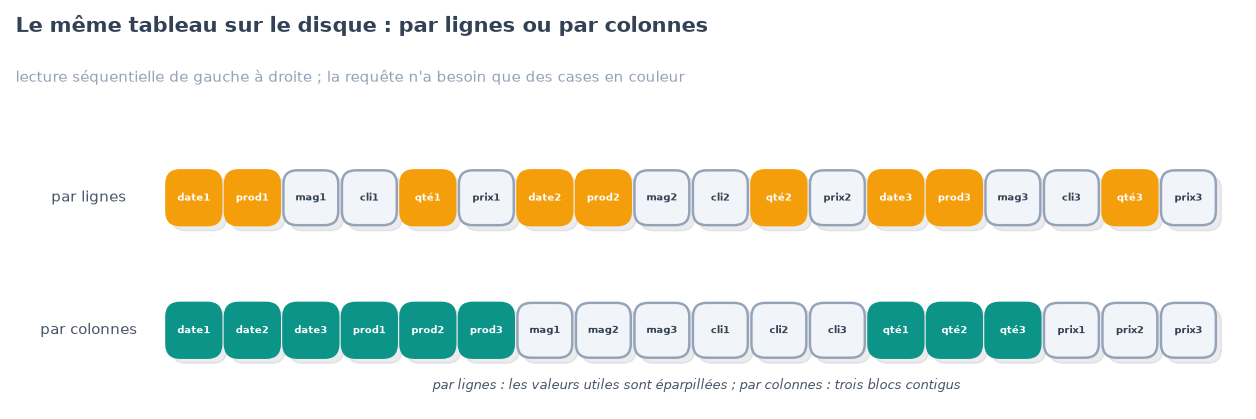

In [3]:
d = Diagram(13.5, 3.4, title="Le même tableau sur le disque : par lignes ou par colonnes",
            subtitle="lecture séquentielle de gauche à droite ; la requête n'a besoin que des cases en couleur")
noms = ["date", "prod", "mag", "cli", "qté", "prix"]
utiles = {"date", "prod", "qté"}
ordre_lignes = [(n_, r) for r in range(1, 4) for n_ in noms]
ordre_cols = [(n_, r) for n_ in noms for r in range(1, 4)]
for y, (titre, seq, coul) in enumerate([("par lignes", ordre_lignes, AMBER), ("par colonnes", ordre_cols, TEAL)]):
    yy = 2.3 - y * 1.45
    d.note(0.85, yy, titre, ha="center", style="normal", fontsize=9.5)
    for k, (n_, r) in enumerate(seq):
        d.box(f"{y}_{k}", 2.0 + k * 0.64, yy, f"{n_}{r}", color=coul if n_ in utiles else GRAY, w=0.6, h=0.6,
              fontsize=6.5, filled=n_ in utiles)
d.note(7.5, 0.25, "par lignes : les valeurs utiles sont éparpillées ; par colonnes : trois blocs contigus",
       fontsize=8.5)
d.show()

**Mesurons.** On range la table de faits de deux façons en mémoire : un tableau
structuré numpy, où chaque ligne occupe 160 octets contigus (20 colonnes de 8 octets),
et des colonnes séparées. Puis on calcule la somme des quantités par catégorie pour
deux catégories.

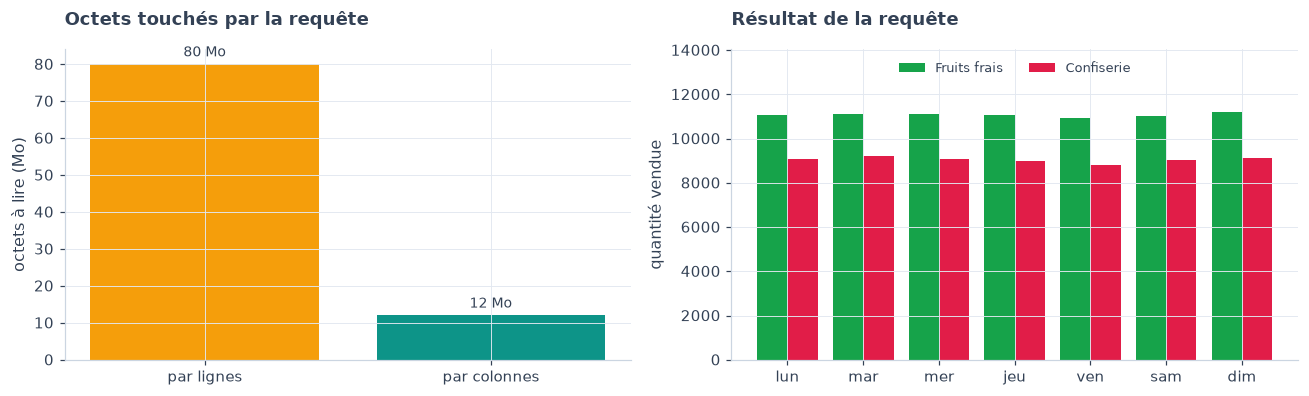

temps de la requête : 7.0 ms en lignes, 4.8 ms en colonnes


In [4]:
lignes = np.empty(len(fact), dtype=[(c, fact[c].dtype) for c in fact.columns])
for c in fact.columns:
    lignes[c] = fact[c].to_numpy()
colonnes = {c: np.ascontiguousarray(fact[c].to_numpy()) for c in fact.columns}
cat_of = dim_product.set_index("product_sk")["category"].to_numpy()
cible = np.isin(cat_of, ["Fruits frais", "Confiserie"])
wd = (dim_date["date"].to_numpy().astype("datetime64[D]").astype(np.int64) + 3) % 7  # lundi = 0


def requete(prod, date, qty):
    m = cible[prod]
    return np.bincount(wd[date[m]] * 2 + (cat_of[prod[m]] == "Confiserie"), weights=qty[m], minlength=14)


t_lignes = meilleur_temps(lambda: requete(lignes["product_sk"], lignes["date_key"], lignes["quantity"]))
t_cols = meilleur_temps(lambda: requete(colonnes["product_sk"], colonnes["date_key"], colonnes["quantity"]))
octets_lignes = lignes.nbytes
octets_cols = sum(colonnes[c].nbytes for c in ["product_sk", "date_key", "quantity"])
res = requete(colonnes["product_sk"], colonnes["date_key"], colonnes["quantity"]).reshape(7, 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
ax = axes[0]
ax.bar(["par lignes", "par colonnes"], [octets_lignes / 1e6, octets_cols / 1e6], color=[AMBER, TEAL])
annotate_bars(ax, "{:.0f} Mo")
ax.set_ylabel("octets à lire (Mo)"); ax.set_title("Octets touchés par la requête")
ax = axes[1]
jours = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
ax.bar(np.arange(7) - 0.2, res[:, 0], 0.4, color=GREEN, label="Fruits frais")
ax.bar(np.arange(7) + 0.2, res[:, 1], 0.4, color=ROSE, label="Confiserie")
ax.set_xticks(range(7), jours); ax.set_ylabel("quantité vendue")
ax.set_title("Résultat de la requête"); ax.set_ylim(0, res.max() * 1.25)
ax.legend(fontsize=8.5, loc="upper center", ncol=2)
finish(fig)
plt.show()
print(f"temps de la requête : {t_lignes * 1e3:.1f} ms en lignes, {t_cols * 1e3:.1f} ms en colonnes")

La requête touche environ sept fois moins d'octets en colonnes (3 colonnes sur 20) et
s'exécute plus vite, même entièrement en mémoire : lire des valeurs espacées de 160
octets gaspille la bande passante mémoire (chaque ligne de cache de 64 octets ne
contient qu'une valeur utile). Sur disque, l'écart de volume se traduit directement en
temps d'E/S. (Les données synthétiques ne montrent pas d'effet du jour de la semaine :
c'est attendu, aucun n'a été simulé.)

En pratique, un moteur en colonnes ne range pas une colonne de mille milliards de
valeurs d'un seul tenant : il découpe la table en **blocs** de milliers ou de millions de
lignes et, dans chaque bloc, range chaque colonne séparément. Les blocs correspondent
souvent à des plages de dates, pour ne charger que ceux d'une période. Parquet, ORC, Apache Arrow, DuckDB, Snowflake, Pinot ou Druid reposent tous sur ce principe.

Ne confondez pas avec le modèle **à colonnes larges** (*wide-column*, Bigtable, HBase,
Cassandra) : malgré le nom, ces bases rangent ensemble toutes les valeurs d'une ligne.

> **À retenir.** Ranger par colonnes permet à une requête analytique de ne lire que les
> quelques colonnes qu'elle utilise sur une table très large : moins d'octets lus sur
> disque et en mémoire.

## 3. La compression des colonnes (section *Column compression*)

Les colonnes sont très **répétitives** : une colonne de produits ne contient que 500
valeurs distinctes sur 500 000 lignes. Trois techniques, souvent combinées :

- **dictionnaire** : remplacer chaque valeur par un petit code entier
  ($\lceil \log_2 n \rceil$ bits pour $n$ valeurs distinctes) ;
- **bitmaps** : pour une colonne à $n$ valeurs distinctes, $n$ bitmaps (un bit par
  ligne : 1 si la ligne a cette valeur) ;
- **codage par plages** (*run-length encoding*, RLE) : les bitmaps sont **creux**
  (surtout des 0) ; on stocke les longueurs des plages successives de 0 et de 1. Des
  techniques comme les *roaring bitmaps* choisissent pour chaque morceau la
  représentation la plus compacte.

Voici le codage d'une petite colonne, dans l'esprit de la figure du livre.

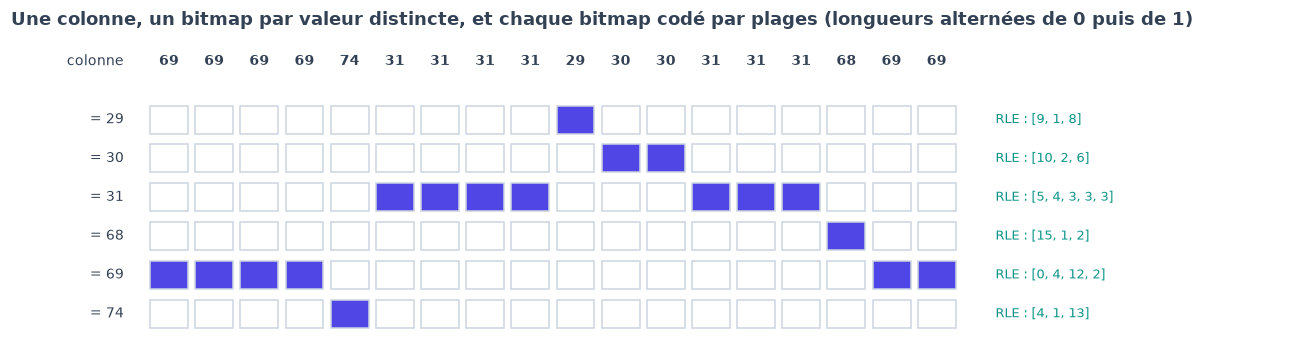

In [5]:
petite = np.array([69, 69, 69, 69, 74, 31, 31, 31, 31, 29, 30, 30, 31, 31, 31, 68, 69, 69])
bm = S.bitmap_index(petite)
fig, ax = plt.subplots(figsize=(12, 3.3))
ax.set_xlim(-3.5, len(petite) + 7); ax.set_ylim(-0.7, len(bm) + 1.2); ax.axis("off")
for j, v in enumerate(petite):
    ax.text(j, len(bm) + 0.5, str(v), ha="center", va="center", fontsize=9, fontweight="bold", color=SLATE)
ax.text(-1, len(bm) + 0.5, "colonne", ha="right", va="center", fontsize=9, color=SLATE)
for r, (val, bits) in enumerate(sorted(bm.items())):
    y = len(bm) - 1 - r
    ax.text(-1, y, f"= {val}", ha="right", va="center", fontsize=9, color=SLATE)
    for j, b in enumerate(bits):
        ax.add_patch(plt.Rectangle((j - 0.42, y - 0.36), 0.84, 0.72, facecolor=INDIGO if b else "white",
                                   edgecolor="#CBD5E1"))
    ax.text(len(petite) + 0.3, y, f"RLE : {S.bitmap_rle_runs(bits)}", va="center", fontsize=8.5, color=TEAL)
ax.set_title("Une colonne, un bitmap par valeur distincte, et chaque bitmap codé par plages "
             "(longueurs alternées de 0 puis de 1)", pad=6)
plt.tight_layout(); plt.show()

Sur notre table, comparons pour quelques colonnes la taille brute (8 octets par valeur),
le dictionnaire, et les bitmaps codés par plages (chaque longueur de plage codée en
varint). La table est dans l'ordre d'insertion, c'est-à-dire triée par date.

In [6]:
def tailles(colonne):
    vals, codes = S.dict_encode(colonne)
    brut = colonne.size * 8
    dico = colonne.size * S.bits_for(len(vals)) / 8 + vals.size * 8
    runs = sum(sum(S.varint_size(r) for r in S.bitmap_rle_runs(b)) for b in S.bitmap_index(codes).values())
    rle_val = S.rle_encode(colonne)[0].size * (8 + 4)
    return dict(distinctes=len(vals), brut_Mo=brut / 1e6, dictionnaire_Mo=dico / 1e6,
                bitmaps_RLE_Mo=runs / 1e6, RLE_direct_Mo=rle_val / 1e6)


comp = pd.DataFrame({c: tailles(fact[c].to_numpy()) for c in ["date_key", "store_sk", "promotion_sk",
                                                              "product_sk", "customer_sk"]}).T
comp

,distinctes,brut_Mo,dictionnaire_Mo,bitmaps_RLE_Mo,RLE_direct_Mo
date_key,365.0,4.0,0.565,0.003,0.004
store_sk,40.0,4.0,0.375,0.991,5.763
promotion_sk,12.0,4.0,0.250,0.287,1.647
product_sk,500.0,4.0,0.567,1.143,5.738
customer_sk,20000.0,4.0,1.097,1.758,6.000


- `date_key` (table triée par date) : 365 longues plages, la colonne se réduit à presque
  rien avec un RLE direct ;
- `store_sk` et `promotion_sk` (peu de valeurs distinctes) : le dictionnaire divise la
  taille par 10 à 20 (6 et 4 bits au lieu de 64) ;
- `product_sk` : 500 bitmaps très creux ; codés par plages, ils occupent pourtant plus
  que le dictionnaire, car dans une colonne non triée presque chaque ligne ouvre une
  nouvelle plage dans l'un des bitmaps. Le RLE devient imbattable quand la colonne est
  triée (section suivante sur l'ordre de tri) ;
- `customer_sk` (20 000 valeurs distinctes, presque toutes différentes d'une ligne à la
  suivante) : les bitmaps n'aident plus, le dictionnaire reste utile.

**Les bitmaps répondent directement aux filtres.** `WHERE product_sk IN (a, b, c)` : OU
des trois bitmaps. `WHERE product_sk = a AND store_sk = b` : ET de deux bitmaps (cela
marche parce que toutes les colonnes gardent le même ordre de lignes). Ces opérations
bit à bit sont extrêmement rapides.

In [7]:
bm_prod = S.bitmap_index(colonnes["product_sk"])
bm_store = S.bitmap_index(colonnes["store_sk"])
populaires = fact.product_sk.value_counts().index[:3].tolist()
ou = bm_prod[populaires[0]] | bm_prod[populaires[1]] | bm_prod[populaires[2]]
et = bm_prod[populaires[0]] & bm_store[3]
pd.DataFrame({"lignes sélectionnées": [int(ou.sum()), int(et.sum())],
              "vérification pandas": [int(fact.product_sk.isin(populaires).sum()),
                                      int(((fact.product_sk == populaires[0]) & (fact.store_sk == 3)).sum())]},
             index=[f"product_sk IN {tuple(populaires)}", f"product_sk = {populaires[0]} AND store_sk = 3"])

,lignes sélectionnées,vérification pandas
"product_sk IN (61, 489, 114)",151751,151751
product_sk = 61 AND store_sk = 3,1156,1156


> **À retenir.** Les colonnes se compressent très bien : dictionnaire pour les petites
> cardinalités, bitmaps codés par plages pour les colonnes creuses, RLE direct pour les
> colonnes triées. Les bitmaps servent aussi d'index pour les filtres (OU, ET).

## 4. Bande passante mémoire et traitement vectorisé (section *Query Execution: Compilation and Vectorization*)

Pour une requête qui parcourt des millions de lignes, le goulot n'est pas seulement le
disque : c'est aussi la bande passante entre mémoire et cache du processeur, les
erreurs de prédiction de branchement et les bulles dans le pipeline d'instructions. Le
stockage en colonnes aide le processeur : un morceau de colonne compressée tient dans le
cache L1, et on le parcourt dans une **boucle serrée**, sans appel de fonction ; les
instructions **SIMD** traitent plusieurs valeurs par instruction. Des opérateurs comme le
ET de deux bitmaps travaillent directement sur les données compressées : c'est le
**traitement vectorisé**, par lots de valeurs plutôt que ligne par ligne.

**Mesurons** le filtre `produit = a ET magasin = b` puis la somme des quantités, de trois
façons : une boucle Python ligne par ligne (le pire des interpréteurs), des opérations
numpy sur colonnes entières (vectorisé, boucles en code natif), et le ET de bitmaps
précalculés.

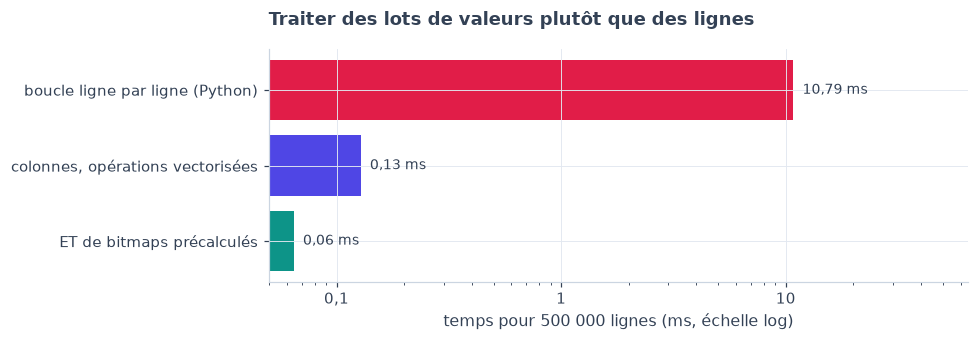

In [8]:
a_, b_ = populaires[0], 3
prod_l, store_l, qty_l = (colonnes[c][:100_000].tolist() for c in ["product_sk", "store_sk", "quantity"])


def boucle_python():
    total = 0
    for p, s, q in zip(prod_l, store_l, qty_l):
        if p == a_ and s == b_:
            total += q
    return total


qty = colonnes["quantity"]
t_py = meilleur_temps(boucle_python, rep=3) * len(qty) / 100_000  # extrapolé à 500 000 lignes
t_np = meilleur_temps(lambda: qty[(colonnes["product_sk"] == a_) & (colonnes["store_sk"] == b_)].sum())
t_bm = meilleur_temps(lambda: qty[bm_prod[a_] & bm_store[b_]].sum())
assert qty[bm_prod[a_] & bm_store[b_]].sum() == qty[(colonnes["product_sk"] == a_) & (colonnes["store_sk"] == b_)].sum()
vec = pd.Series({"boucle ligne par ligne (Python)": t_py, "colonnes, opérations vectorisées": t_np,
                 "ET de bitmaps précalculés": t_bm}) * 1e3
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(range(3), vec.values, color=[ROSE, INDIGO, TEAL])
ax.set_yticks(range(3), vec.index); ax.invert_yaxis()
ax.set_xscale("log"); S.plain_log_ticks(ax, "x")
for y, v in enumerate(vec.values):
    ax.text(v * 1.1, y, f"{v:.2f} ms".replace(".", ","), va="center", fontsize=9)
ax.set_xlim(right=vec.max() * 6)
ax.set_xlabel("temps pour 500 000 lignes (ms, échelle log)")
ax.set_title("Traiter des lots de valeurs plutôt que des lignes")
plt.tight_layout(); plt.show()

Près de deux ordres de grandeur séparent la boucle ligne par ligne des opérations
vectorisées. Une partie de l'écart vient de l'interprète Python lui-même, mais c'est
précisément le point : un moteur qui interprète la requête valeur par valeur paie un
surcoût par valeur, alors qu'un opérateur vectorisé l'amortit sur des milliers de
valeurs. Le ET de bitmaps précalculés évite même les comparaisons.

> **À retenir.** Le stockage en colonnes économise aussi le processeur : boucles serrées
> sur des données contiguës et compressées, SIMD, opérateurs appliqués par lots.

## 5. L'ordre de tri (section *Sort order in column storage*)

L'ordre des lignes est libre : le plus simple est l'ordre d'insertion. Mais on peut
**trier** la table, comme une SSTable, et s'en servir comme d'un index. Attention : on
ne trie pas chaque colonne indépendamment (on ne saurait plus quelles valeurs forment une
ligne) ; on trie des **lignes entières**, rangées ensuite par colonnes.

- Si les requêtes portent souvent sur des plages de dates, `date_key` en **première clé
  de tri** permet de ne lire que les lignes du dernier mois.
- Une **deuxième clé** (par exemple `product_sk`) range ensemble les ventes d'un même
  produit le même jour.
- Bonus : la première clé de tri forme de **longues plages** de valeurs identiques, que
  le RLE compresse à l'extrême ; l'effet s'atténue pour les clés suivantes.

Mesurons la taille du RLE direct de chaque colonne pour trois ordres de tri.

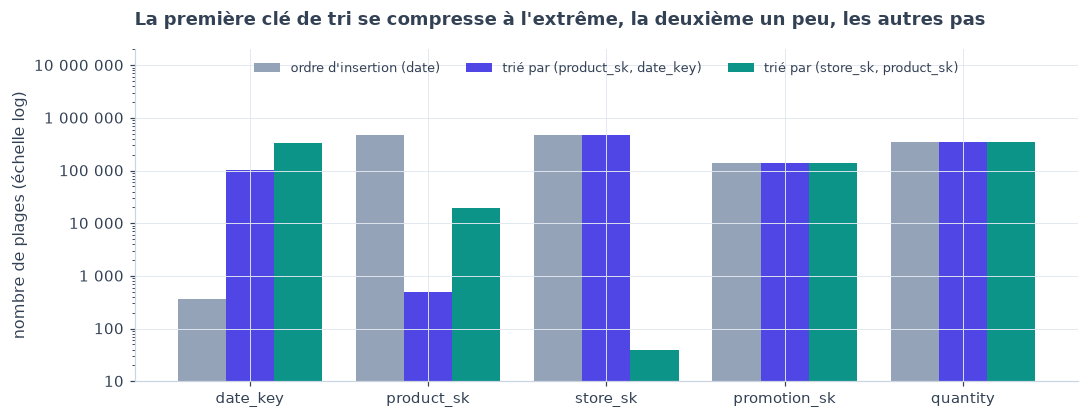

ordre,ordre d'insertion (date),"trié par (product_sk, date_key)","trié par (store_sk, product_sk)"
colonne,,,
date_key,365,104813,330986
product_sk,478159,500,19440
store_sk,480235,480589,40
promotion_sk,137266,136999,137100
quantity,355147,355164,355063


In [9]:
ordres = {"ordre d'insertion (date)": None, "trié par (product_sk, date_key)": ["product_sk", "date_key"],
          "trié par (store_sk, product_sk)": ["store_sk", "product_sk"]}
cols_mesurees = ["date_key", "product_sk", "store_sk", "promotion_sk", "quantity"]
rows = []
for nom, cles in ordres.items():
    t = fact if cles is None else fact.sort_values(cles, kind="stable")
    for c in cols_mesurees:
        rows.append(dict(ordre=nom, colonne=c, plages=S.rle_encode(t[c].to_numpy())[0].size))
tri = pd.DataFrame(rows).pivot(index="colonne", columns="ordre", values="plages").loc[cols_mesurees]
fig, ax = plt.subplots(figsize=(10, 3.9))
x = np.arange(len(tri))
for j, (nom, c) in enumerate(zip(ordres, [GRAY, INDIGO, TEAL])):
    ax.bar(x + (j - 1) * 0.27, tri[nom], 0.27, color=c, label=nom)
ax.set_yscale("log"); S.plain_log_ticks(ax)
ax.set_xticks(x, tri.index)
ax.set_ylabel("nombre de plages (échelle log)")
ax.set_title("La première clé de tri se compresse à l'extrême, la deuxième un peu, les autres pas")
ax.set_ylim(10, 2e7)
ax.legend(fontsize=8.5, loc="upper center", ncol=3)
plt.tight_layout(); plt.show()
tri

Triée par `(product_sk, date_key)`, la colonne `product_sk` ne compte plus que 500
plages (une par produit) ; `date_key`, deuxième clé, passe de 365 plages (elle était la
clé de tri implicite) à environ 105 000 : une par couple (produit, jour) présent. De même,
triée par `(store_sk, product_sk)`, la première clé n'a que 40 plages et la deuxième
environ 19 000. Les colonnes qui ne sont pas des clés de tri (`promotion_sk`,
`quantity`) ne gagnent rien : elles changent presque à chaque ligne.

> **À retenir.** Trier des lignes entières selon une ou deux clés choisies d'après les
> requêtes sert à la fois d'index (plages de dates) et de compression (longues plages
> de valeurs identiques sur la première clé).

## 6. Écrire dans un stockage en colonnes (section *Writing to column-oriented storage*)

Colonnes, compression et tri accélèrent les lectures mais compliquent les écritures :
insérer **une** ligne au milieu d'une table triée et compressée obligerait à réécrire
toutes les colonnes à partir du point d'insertion. Les écritures d'un entrepôt sont
heureusement le plus souvent des **imports en masse** (ETL) : réécrire les colonnes une
fois pour un lot de $B$ lignes amortit le coût. La solution est celle des arbres LSM :
les écritures vont d'abord dans une structure **en mémoire, par lignes et triée** ;
quand elle est assez grosse, on la **fusionne** avec les fichiers en colonnes et on
écrit de **nouveaux** fichiers d'un seul trait. Les requêtes combinent les deux sources,
de façon invisible pour l'analyste.

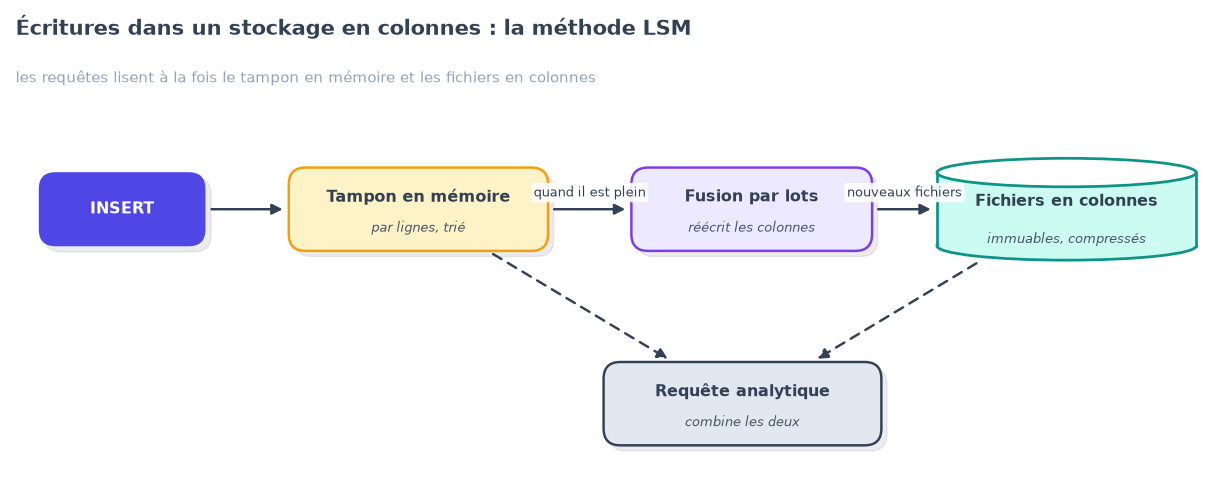

In [10]:
d = Diagram(13, 4.2, title="Écritures dans un stockage en colonnes : la méthode LSM",
            subtitle="les requêtes lisent à la fois le tampon en mémoire et les fichiers en colonnes")
d.box("w", 1.2, 3.0, "INSERT", color=INDIGO, kind="tag", w=1.8, h=0.8)
d.box("buf", 4.4, 3.0, "Tampon en mémoire", sub="par lignes, trié", color=AMBER, w=2.8)
d.box("merge", 8.0, 3.0, "Fusion par lots", sub="réécrit les colonnes", color=VIOLET, w=2.6)
d.box("files", 11.4, 3.0, "Fichiers en colonnes", sub="immuables, compressés", color=TEAL, kind="db", w=2.8,
      h=1.1)
d.box("q", 7.9, 0.9, "Requête analytique", sub="combine les deux", color=SLATE, w=3.0)
d.arrow("w", "buf"); d.arrow("buf", "merge", "quand il est plein"); d.arrow("merge", "files", "nouveaux fichiers")
d.arrow("buf", "q", style="dashed", color=SLATE); d.arrow("files", "q", style="dashed", color=SLATE)
d.show()

Chiffrons l'amortissement : une colonne triée de $N$ valeurs reçoit des insertions à des
positions aléatoires. Insérée seule, chaque ligne déplace en moyenne $N/2$ valeurs ;
par lots de $B$ lignes, une fusion réécrit $N + B$ valeurs pour $B$ lignes. On mesure
aussi le temps réel avec numpy (`np.insert` ligne à ligne contre fusion d'un lot trié).

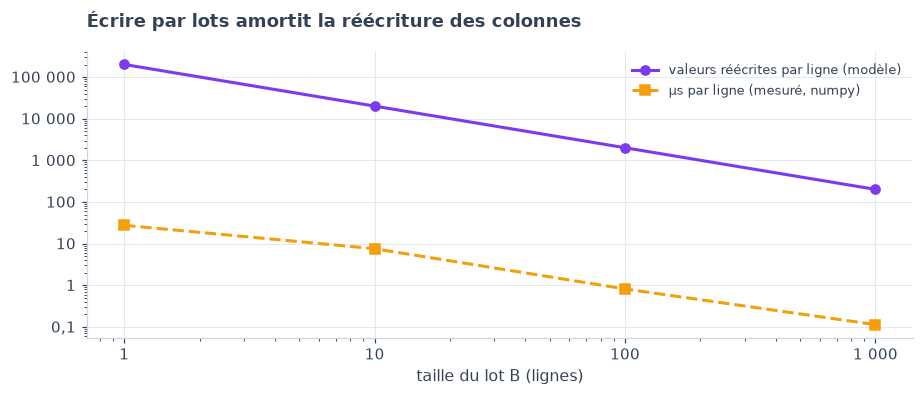

,taille_du_lot,valeurs_reecrites_par_ligne,us_par_ligne
0,1,201000.0,27.579
1,10,20100.0,7.566
2,100,2010.0,0.818
3,1000,201.0,0.114


In [11]:
N0 = 200_000
base = np.sort(np.random.default_rng(0).integers(0, 10**9, N0))
nouvelles = np.random.default_rng(1).integers(0, 10**9, 2_000)
rows = []
for B in [1, 10, 100, 1_000]:
    col = base.copy()
    t0 = time.perf_counter()
    for i in range(0, len(nouvelles), B):
        lot = np.sort(nouvelles[i:i + B])
        pos = np.searchsorted(col, lot)
        col = np.insert(col, pos, lot)
    dt_ = time.perf_counter() - t0
    rows.append(dict(taille_du_lot=B, valeurs_reecrites_par_ligne=(N0 + len(nouvelles) / 2) / B,
                     us_par_ligne=dt_ / len(nouvelles) * 1e6))
lots = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.7))
ax.loglog(lots.taille_du_lot, lots.valeurs_reecrites_par_ligne, "o-", color=VIOLET, label="valeurs réécrites par ligne (modèle)")
ax.loglog(lots.taille_du_lot, lots.us_par_ligne, "s--", color=AMBER, label="µs par ligne (mesuré, numpy)")
S.plain_log_ticks(ax, "both")
ax.set_xlabel("taille du lot B (lignes)"); ax.set_title("Écrire par lots amortit la réécriture des colonnes")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()
lots

Le coût par ligne décroît comme $1/B$ : par lots de 1 000 lignes, chaque ligne coûte
environ mille fois moins de réécriture qu'insérée seule. Le temps mesuré baisse un peu
moins vite (d'un facteur 250 environ), car pour de petits lots le coût fixe de chaque
appel numpy pèse aussi. C'est pourquoi les entrepôts
en colonnes (Vertica, et bien d'autres) passent par un tampon en mémoire. Les fichiers étant immuables et écrits d'un seul trait, le stockage objet leur convient bien.

> **À retenir.** Un stockage en colonnes écrit par lots : tampon trié en mémoire, puis
> fusion vers de nouveaux fichiers en colonnes, comme un arbre LSM.

## 7. Vues matérialisées et cubes de données (section *Materialized Views and Data Cubes*)

**Vue virtuelle ou matérialisée.** Une vue virtuelle n'est qu'un raccourci : la base
remplace la vue par sa requête au moment de l'exécution. Une **vue matérialisée** est une
vraie **copie du résultat**, écrite sur disque ; il faut la mettre à jour quand les
données sous-jacentes changent (plus de travail à l'écriture, des lectures plus
rapides).

**Cube de données.** Les requêtes analytiques reviennent souvent aux mêmes agrégats
(`SUM`, `COUNT`, `AVG`...). Pourquoi ne pas les précalculer ? Un **cube de données** (ou
cube OLAP) est une grille d'agrégats selon plusieurs dimensions. Avec deux dimensions
(date et produit), chaque case contient la somme des ventes de ce produit ce jour-là ;
en sommant une ligne ou une colonne, on obtient un agrégat réduit d'une dimension (ventes
par produit toutes dates confondues, ou par date tous produits confondus).

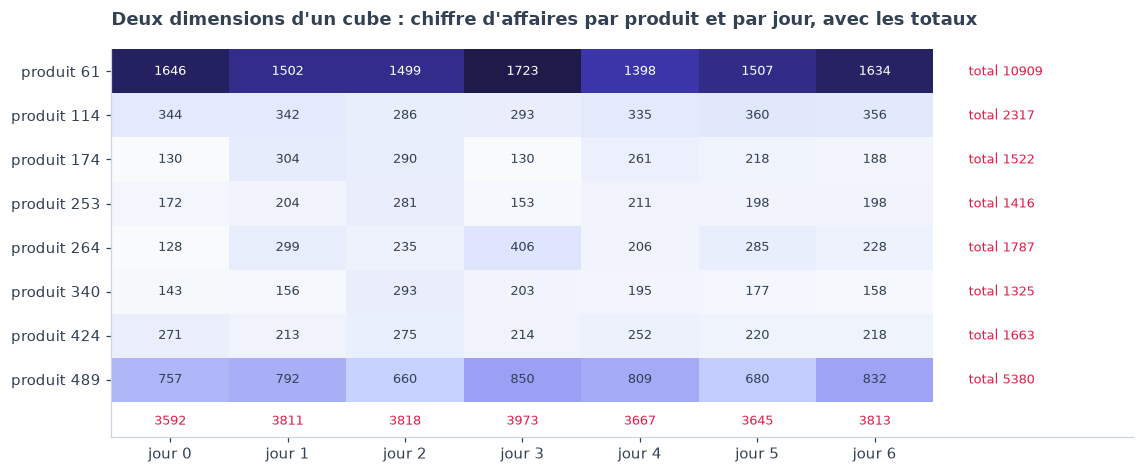

In [12]:
semaine = fact[fact.date_key < 7]
top = semaine.groupby("product_sk").net_price.sum().nlargest(8).index
cube2 = semaine[semaine.product_sk.isin(top)].pivot_table(index="product_sk", columns="date_key",
                                                          values="net_price", aggfunc="sum", fill_value=0)
fig, ax = plt.subplots(figsize=(10.5, 4.4))
ax.imshow(cube2.values, cmap="ddia_seq", aspect="auto")
for i in range(cube2.shape[0]):
    for j in range(cube2.shape[1]):
        v = cube2.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                color="white" if v > cube2.values.max() * 0.6 else SLATE)
    ax.text(cube2.shape[1] - 0.2, i, f"total {cube2.values[i].sum():.0f}", va="center", fontsize=8.5, color=ROSE,
            ha="left")
for j in range(cube2.shape[1]):
    ax.text(j, cube2.shape[0] - 0.2, f"{cube2.values[:, j].sum():.0f}", ha="center", va="top", fontsize=8.5,
            color=ROSE)
ax.set_xticks(range(cube2.shape[1]), [f"jour {d}" for d in cube2.columns])
ax.set_yticks(range(cube2.shape[0]), [f"produit {p}" for p in cube2.index])
ax.set_xlim(-0.5, cube2.shape[1] + 1.2); ax.set_ylim(cube2.shape[0] + 0.3, -0.5)
ax.grid(False)
ax.set_title("Deux dimensions d'un cube : chiffre d'affaires par produit et par jour, avec les totaux")
plt.tight_layout(); plt.show()

En général les faits ont plus de deux dimensions (date, produit, magasin, promotion,
client : cinq dans le schéma en étoile). Un cube à $d$ dimensions se résume selon chaque
sous-ensemble de dimensions : $2^d$ agrégats possibles, qui forment un **treillis**. Le
schéma montre celui de trois dimensions.

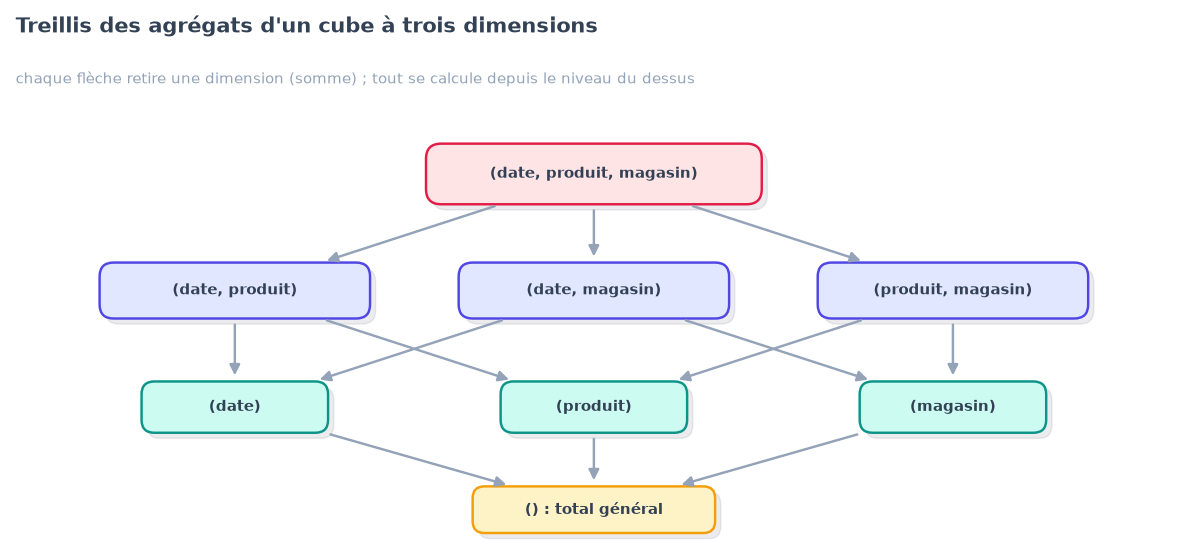

In [13]:
d = Diagram(12.5, 4.8, title="Treillis des agrégats d'un cube à trois dimensions",
            subtitle="chaque flèche retire une dimension (somme) ; tout se calcule depuis le niveau du dessus")
d.box("dps", 6.25, 4.0, "(date, produit, magasin)", color=ROSE, w=3.6, h=0.65, fontsize=9.5)
for j, (nm, t) in enumerate([("dp", "(date, produit)"), ("ds", "(date, magasin)"), ("ps", "(produit, magasin)")]):
    d.box(nm, 2.4 + j * 3.85, 2.75, t, color=INDIGO, w=2.9, h=0.6, fontsize=9.5)
    d.arrow("dps", nm, color=GRAY)
for j, (nm, t, par) in enumerate([("d", "(date)", ["dp", "ds"]), ("p", "(produit)", ["dp", "ps"]),
                                  ("s", "(magasin)", ["ds", "ps"])]):
    d.box(nm, 2.4 + j * 3.85, 1.5, t, color=TEAL, w=2.0, h=0.55, fontsize=9.5)
    for pp in par:
        d.arrow(pp, nm, color=GRAY)
d.box("all", 6.25, 0.4, "() : total général", color=AMBER, w=2.6, h=0.5, fontsize=9.5)
for nm in ["d", "p", "s"]:
    d.arrow(nm, "all", color=GRAY)
d.show()

**Le gain et la limite.** Mesurons « chiffre d'affaires par magasin le dernier jour »
sur les données brutes et sur le cube précalculé (`S.data_cube`).

In [14]:
t0 = time.perf_counter()
cube = S.data_cube(fact, ["date_key", "product_sk", "store_sk"], "net_price")
t_cube_build = time.perf_counter() - t0
dernier = fact.date_key.max()
t_brut = meilleur_temps(lambda: fact[fact.date_key == dernier].groupby("store_sk").net_price.sum())
vue = cube[("date_key", "store_sk")]
t_cube = meilleur_temps(lambda: vue.loc[dernier])
assert np.allclose(vue.loc[dernier].values, fact[fact.date_key == dernier].groupby("store_sk").net_price.sum().values)
pd.DataFrame({"temps (ms)": [t_brut * 1e3, t_cube * 1e3, t_cube_build * 1e3],
              "lignes lues": [len(fact), len(vue.loc[dernier]), len(fact) * len(cube)]},
             index=["requête sur les données brutes", "lecture dans le cube (date, magasin)",
                    "construction des 8 agrégats du cube (une fois)"])

,temps (ms),lignes lues
requête sur les données brutes,0.365,500000
"lecture dans le cube (date, magasin)",0.022,40
construction des 8 agrégats du cube (une fois),59.657,4000000


La lecture dans le cube ne touche qu'une poignée de cases précalculées. Mais le cube est
**rigide** : impossible de répondre à « quelle part des ventes vient d'articles à plus de
100 € ? », car le prix n'est pas une dimension. Les entrepôts gardent donc le plus de
données brutes possible et n'utilisent les cubes que comme accélérateurs pour certaines
requêtes fréquentes.

> **À retenir.** Une vue matérialisée stocke le résultat d'une requête et doit être
> maintenue à l'écriture. Le cube précalcule les agrégats selon toutes les combinaisons de
> dimensions : lectures instantanées, mais seulement pour les questions prévues.

## 8. L'exécution des requêtes : interprétation, compilation, vectorisation (section *Query Execution: Compilation and Vectorization*)

Une requête SQL analytique devient un **plan** fait d'**opérateurs** (filtres, jointures,
agrégations), éventuellement répartis sur plusieurs machines. À l'intérieur d'un
opérateur, le moteur le plus simple est un **interpréteur** : pour chaque ligne, il
consulte la structure de la requête pour savoir quelles comparaisons faire sur quelles
colonnes. C'est trop lent pour l'analytique. Deux réponses :

- **la compilation de requêtes** : le moteur génère du code spécialisé pour **cette**
  requête (une boucle sur les lignes avec les comparaisons écrites en dur), puis le
  compile en code machine (souvent avec LLVM), comme un compilateur à la volée de la
  JVM ;
- **le traitement vectorisé** (section 4) : la requête reste interprétée, mais chaque
  opérateur prédéfini traite un **lot** de valeurs d'une colonne (comparaison qui produit
  un bitmap, ET de bitmaps...).

Les deux approches exploitent les mêmes propriétés des processeurs : accès mémoire
séquentiels, boucles serrées sans appel de fonction, parallélisme (fils, SIMD), travail
direct sur les données compressées. Simulons-les en Python : `S.interpret_query`
interprète un petit plan ligne par ligne, `S.compile_query` génère et compile une
fonction spécialisée, et numpy joue le rôle du moteur vectorisé.

def query(product_sk, promotion_sk, quantity, store_sk):
    total = 0
    for i in range(len(quantity)):
        if product_sk[i] == 61 and store_sk[i] in (1, 2, 3) and promotion_sk[i] == 0:
            total += quantity[i]
    return total



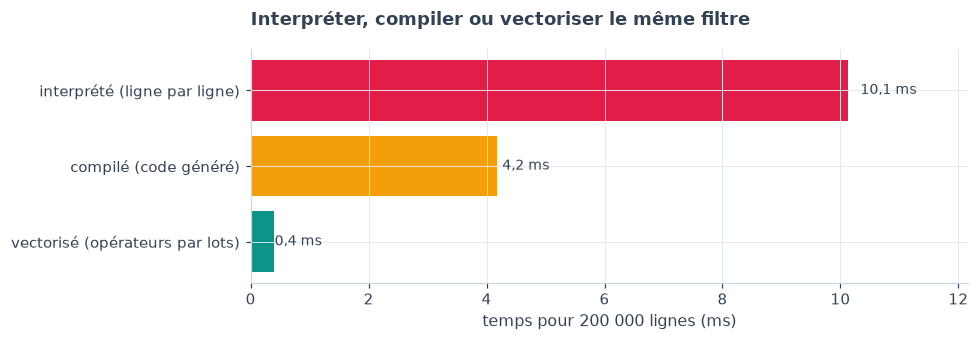

In [15]:
n_q = 200_000
cols_py = {c: colonnes[c][:n_q].tolist() for c in ["product_sk", "store_sk", "promotion_sk", "quantity"]}
where = [("product_sk", "=", int(a_)), ("store_sk", "in", (1, 2, 3)), ("promotion_sk", "=", 0)]
fn, source = S.compile_query(where, "quantity")
print(source)
res_i = S.interpret_query(cols_py, where, "quantity")
res_c = fn(cols_py)
cols_np = {c: colonnes[c][:n_q] for c in cols_py}


def vectorise():
    m = (cols_np["product_sk"] == a_) & np.isin(cols_np["store_sk"], (1, 2, 3)) & (cols_np["promotion_sk"] == 0)
    return int(cols_np["quantity"][m].sum())


assert res_i == res_c == vectorise()
ex = pd.Series({"interprété (ligne par ligne)": meilleur_temps(lambda: S.interpret_query(cols_py, where, "quantity"), 3),
                "compilé (code généré)": meilleur_temps(lambda: fn(cols_py), 3),
                "vectorisé (opérateurs par lots)": meilleur_temps(vectorise, 3)}) * 1e3
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(range(3), ex.values, color=[ROSE, AMBER, TEAL])
ax.set_yticks(range(3), ex.index); ax.invert_yaxis()
for y, v in enumerate(ex.values):
    ax.text(v * 1.02, y, f"{v:.1f} ms".replace(".", ","), va="center", fontsize=9)
ax.set_xlim(right=ex.max() * 1.2)
ax.set_xlabel(f"temps pour {n_q:,} lignes (ms)".replace(",", " "))
ax.set_title("Interpréter, compiler ou vectoriser le même filtre")
plt.tight_layout(); plt.show()

Le code généré supprime le surcoût d'interprétation (parcours du plan, appels de
fonctions par comparaison) : il est nettement plus rapide que l'interpréteur, même en
restant du bytecode Python. L'approche vectorisée gagne encore beaucoup ici, car numpy
exécute ses boucles en code natif ; un vrai moteur compilé (LLVM) rattraperait cet écart.
Dans les vrais systèmes, les deux approches coexistent et donnent des performances
comparables, avec des implémentations très différentes.

> **À retenir.** Pour réduire le coût processeur d'une requête analytique, on compile la
> requête en code spécialisé, ou on la vectorise (opérateurs prédéfinis appliqués par
> lots). Les deux visent des boucles serrées sur des données contiguës.

## 9. Les entrepôts de données dans le cloud (section *Cloud Data Warehouses*)

Aux entrepôts historiques (Teradata, Vertica, SAP HANA) se sont ajoutés des entrepôts
**nés dans le cloud** : BigQuery, Redshift, Snowflake. Ils s'appuient sur le **stockage
objet** et le calcul **serverless**, s'intègrent aux autres services du fournisseur, et
surtout **séparent le calcul du stockage** : les données vivent dans le stockage objet,
et l'on ajuste indépendamment la capacité de stockage et la puissance de calcul allouée à
chaque requête.

Le monde open source (Hive, Trino, Spark) a suivi en **découpant** l'entrepôt en
composants indépendants, autour d'un lac de données (*data lake*) sur stockage objet :

- le **moteur de requêtes** (Trino, Presto, DataFusion) analyse le SQL, l'optimise et
  l'exécute, souvent de façon distribuée ;
- le **format de stockage** (Parquet, ORC, Lance, Nimble) code les lignes d'une table en
  fichiers, en colonnes, lisibles par d'autres outils que le moteur ;
- le **format de table** (Apache Iceberg, Delta) dit quels fichiers immuables
  constituent une table, avec son schéma ; il permet insertions et suppressions, voyage
  dans le temps et même des transactions ;
- le **catalogue** (Polaris, Unity Catalog, catalogue Iceberg) dit quelles tables
  forment une base ; souvent un service REST séparé, consultable aussi par les outils de
  gouvernance des données.

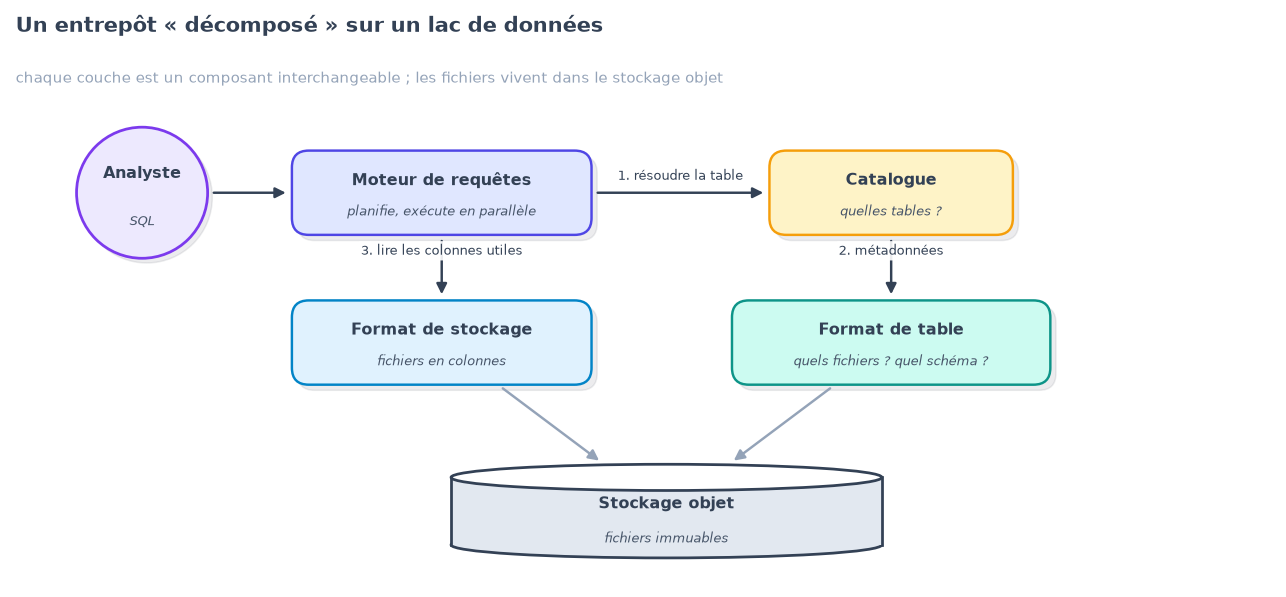

In [16]:
d = Diagram(13.5, 5.2, title="Un entrepôt « décomposé » sur un lac de données",
            subtitle="chaque couche est un composant interchangeable ; les fichiers vivent dans le stockage objet")
d.box("sql", 1.4, 4.2, "Analyste", sub="SQL", color=VIOLET, kind="user", w=1.4)
d.box("qe", 4.6, 4.2, "Moteur de requêtes", sub="planifie, exécute en parallèle", color=INDIGO, w=3.2)
d.box("cat", 9.4, 4.2, "Catalogue", sub="quelles tables ?", color=AMBER, w=2.6)
d.box("tf", 9.4, 2.6, "Format de table", sub="quels fichiers ? quel schéma ?", color=TEAL, w=3.4)
d.box("sf", 4.6, 2.6, "Format de stockage", sub="fichiers en colonnes", color=SKY, w=3.2)
d.box("obj", 7.0, 0.8, "Stockage objet", sub="fichiers immuables", color=SLATE, kind="db", w=4.6, h=1.0)
d.arrow("sql", "qe"); d.arrow("qe", "cat", "1. résoudre la table")
d.arrow("cat", "tf", "2. métadonnées")
d.arrow("qe", "sf", "3. lire les colonnes utiles")
d.arrow("sf", "obj", color=GRAY); d.arrow("tf", "obj", color=GRAY)
d.show()

**Pourquoi séparer calcul et stockage ?** Un ordre de grandeur suffit. Supposons qu'une
requête doive parcourir 2 To de colonnes compressées et qu'un nœud de calcul lise le
stockage objet à environ 1 Go/s. Le temps de la requête est inversement proportionnel au
nombre de nœuds alloués, alors que son coût (nœuds × durée) reste à peu près constant :
on peut louer beaucoup de nœuds quelques secondes au lieu de quelques nœuds pendant de
longues minutes, sans rien changer au stockage.

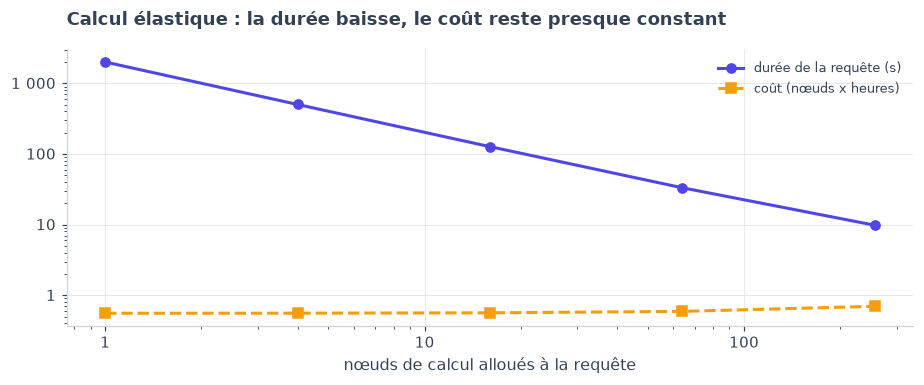

In [17]:
volume_go, debit_noeud = 2000, 1.0
noeuds = np.array([1, 4, 16, 64, 256])
duree = volume_go / (debit_noeud * noeuds) + 2.0  # 2 s de démarrage et de coordination
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.loglog(noeuds, duree, "o-", color=INDIGO, label="durée de la requête (s)")
ax.loglog(noeuds, duree * noeuds / 3600, "s--", color=AMBER, label="coût (nœuds x heures)")
S.plain_log_ticks(ax, "both")
ax.set_xlabel("nœuds de calcul alloués à la requête")
ax.set_title("Calcul élastique : la durée baisse, le coût reste presque constant")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

> **À retenir.** Les entrepôts cloud séparent calcul et stockage (objet) ; l'écosystème
> ouvert se décompose en moteur de requêtes, format de stockage en colonnes, format de
> table et catalogue, tous interchangeables.

## Synthèse

- Les requêtes analytiques lisent beaucoup de lignes mais peu de colonnes : le
  **stockage en colonnes** ne lit que celles-ci.
- Les colonnes se **compressent** très bien (dictionnaire, bitmaps, RLE), et les bitmaps
  servent d'index pour les filtres.
- Le **traitement vectorisé** (boucles serrées, SIMD, données compressées) et la
  **compilation de requêtes** économisent le processeur.
- **Trier** les lignes sert d'index et de compression ; les **écritures** passent par un
  tampon en mémoire fusionné par lots, comme un LSM.
- **Vues matérialisées** et **cubes** précalculent des agrégats : rapides mais rigides.
- Les **entrepôts cloud** séparent calcul et stockage ; l'écosystème ouvert se découpe en
  moteur, format de stockage, format de table et catalogue.

**Liens.** Le traitement par lots (chapitre 11) produit et lit massivement ces
fichiers en colonnes ; la maintenance incrémentale des vues matérialisées revient avec
le traitement de flux (chapitre 12).